# Milestone 5 -- Ensembling

**Goals**
1. Extracting and sorting logits to get the top-3 predictions
2. Ensemble techniques to stack predictions from multiple models
3. Other strategies to improve predictions

Every model built across milestones 1-4 is re-scored on **the exact same
80-question validation split milestone 4 held out** (`train.csv.sample(n=400,
random_state=42)`, rows 320-399) -- the one set none of them (including the
LoRA adapter) were fit on, so the comparison and the ensemble evaluation
are both leakage-free.


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import joblib
from datasets import Dataset
from transformers import AutoTokenizer, AutoModel, AutoModelForMultipleChoice, pipeline
from peft import PeftModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from text_processing import OPTION_COLS
from embeddings import embed_texts, cosine_sim_rows
from mcq_formatting import preprocess_for_multiple_choice, DataCollatorForMultipleChoice
from metrics import mean_average_precision_at_k
from ensembling import softmax_rows, average_probabilities, rankings_from_scores, borda_fusion, reciprocal_rank_fusion, long_to_wide_scores

torch.manual_seed(42)

data = pd.read_csv('../data/train.csv').sample(n=400, random_state=42).reset_index(drop=True)
val_df = data.iloc[320:].reset_index(drop=True)   # same 80 rows milestone-4 evaluated on, untouched by LoRA training
true_answers = val_df['answer'].tolist()
print('eval set:', val_df.shape)

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\torch\cuda\__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


eval set: (80, 8)


## 1. Extracting and sorting logits for top-3 predictions

The mechanical core of every "which 3 options" decision in this project:
given a model's raw per-option scores (logits, cosine similarities,
probabilities -- whatever scale), sort descending and take the option
letters of the top 3.

In [2]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')
lora_model = PeftModel.from_pretrained(
    AutoModelForMultipleChoice.from_pretrained('distilbert-base-uncased'),
    '../models/milestone4_lora_adapter',
)
lora_model.eval()

demo_ds = Dataset.from_pandas(val_df.iloc[[0]])
demo_tok = demo_ds.map(lambda ex: preprocess_for_multiple_choice(ex, tokenizer, 48), batched=True, remove_columns=demo_ds.column_names)
collator = DataCollatorForMultipleChoice(tokenizer=tokenizer)
batch = collator([demo_tok[0]])

with torch.no_grad():
    logits = lora_model(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'], token_type_ids=batch.get('token_type_ids')).logits

print('raw logits:', logits.numpy().round(3))
sorted_idx = torch.argsort(logits, dim=1, descending=True).numpy()[0]
top3 = ' '.join(OPTION_COLS[i] for i in sorted_idx[:3])
print(f'sorted option order: {[OPTION_COLS[i] for i in sorted_idx]}')
print(f'top-3 prediction string (competition submission format): "{top3}"')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6362.24it/s]


[transformers] DistilBertForMultipleChoice LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Map: 100%|██████████| 1/1 [00:00<00:00, 99.33 examples/s]

raw logits: [[0.376 0.375 0.376 0.376 0.375]]
sorted option order: ['A', 'C', 'D', 'B', 'E']
top-3 prediction string (competition submission format): "A C D"


## 2. Scoring every model on the same 80-question set

Five models, five different kinds of score, all reduced to a
`(80, 5)` per-option score table so they can be compared and combined
on equal footing.

In [3]:
# Model 1: the very first baseline -- TF-IDF/length-overlap features + LogisticRegression
# (models/baseline.joblib, trained on the *full* 2000-row train set, from the initial repo scaffold)
from utils import to_long_format, add_features as add_features_baseline, FEATURE_COLS as BASELINE_FEATURE_COLS

bundle = joblib.load('../models/baseline.joblib')
baseline_model, baseline_vectorizer = bundle['model'], bundle['vectorizer']

long_df = to_long_format(val_df, has_labels=False)
long_df, _ = add_features_baseline(long_df, vectorizer=baseline_vectorizer, fit_vectorizer=False)
baseline_probs_1d = baseline_model.predict_proba(long_df[BASELINE_FEATURE_COLS])[:, 1]
scores_baseline = long_to_wide_scores(long_df['id'], long_df['option'], baseline_probs_1d)
scores_baseline = scores_baseline.loc[val_df['id']].reset_index(drop=True)
probs_baseline = softmax_rows(scores_baseline, temperature=0.1)  # probabilities already; sharpen slightly for comparability
print('Model 1 (baseline LogReg) done')

Model 1 (baseline LogReg) done


In [4]:
# Model 2: TF-IDF cosine similarity (milestone 1/2 style, refit on this val set's own vocabulary)
all_text = pd.concat([val_df[c].astype(str) for c in ['prompt'] + OPTION_COLS], ignore_index=True)
tfidf = TfidfVectorizer(min_df=1)
tfidf.fit(all_text)
prompt_vecs = tfidf.transform(val_df['prompt'].astype(str))
scores_tfidf = pd.DataFrame({
    opt: np.asarray(prompt_vecs.multiply(tfidf.transform(val_df[opt].astype(str))).sum(axis=1)).ravel()
    for opt in OPTION_COLS
})
probs_tfidf = softmax_rows(scores_tfidf, temperature=0.1)
print('Model 2 (TF-IDF cosine) done')

Model 2 (TF-IDF cosine) done


In [5]:
# Model 3: pretrained DistilBERT embedding cosine similarity (milestone 2)
embed_model = AutoModel.from_pretrained('distilbert-base-uncased')
prompt_emb = embed_texts(val_df['prompt'].tolist(), tokenizer, embed_model, batch_size=64, max_length=96)
option_embs = {opt: embed_texts(val_df[opt].astype(str).tolist(), tokenizer, embed_model, batch_size=64, max_length=96) for opt in OPTION_COLS}
scores_bert = pd.DataFrame({opt: cosine_sim_rows(prompt_emb, option_embs[opt]) for opt in OPTION_COLS})
probs_bert = softmax_rows(scores_bert, temperature=0.05)
print('Model 3 (DistilBERT cosine) done')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6821.67it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model 3 (DistilBERT cosine) done


In [6]:
# Model 4: zero-shot NLI (milestone 2/3)
zero_shot = pipeline('zero-shot-classification', model='typeform/distilbert-base-uncased-mnli')
zs_rows = []
for _, row in val_df.iterrows():
    options = [row[c] for c in OPTION_COLS]
    result = zero_shot(row['prompt'], candidate_labels=options, hypothesis_template='The correct answer is: {}.')
    label_to_score = dict(zip(result['labels'], result['scores']))
    zs_rows.append([label_to_score[row[c]] for c in OPTION_COLS])
probs_zeroshot = pd.DataFrame(zs_rows, columns=OPTION_COLS)  # already a probability distribution over the 5 options
print('Model 4 (zero-shot NLI) done')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 5746.53it/s]

Model 4 (zero-shot NLI) done


In [7]:
# Model 5: LoRA fine-tuned classifier (milestone 4)
val_ds = Dataset.from_pandas(val_df)
val_tok = val_ds.map(lambda ex: preprocess_for_multiple_choice(ex, tokenizer, 48), batched=True, remove_columns=val_ds.column_names)
batch = collator([val_tok[i] for i in range(len(val_tok))])
with torch.no_grad():
    lora_logits = lora_model(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'], token_type_ids=batch.get('token_type_ids')).logits
scores_lora = pd.DataFrame(lora_logits.numpy(), columns=OPTION_COLS)
probs_lora = softmax_rows(scores_lora, temperature=1.0)
print('Model 5 (LoRA fine-tuned) done')

Map:   0%|          | 0/80 [00:00<?, ? examples/s]

Map: 100%|██████████| 80/80 [00:00<00:00, 753.74 examples/s]

Map: 100%|██████████| 80/80 [00:00<00:00, 724.28 examples/s]

Model 5 (LoRA fine-tuned) done


## 3. Individual model mAP@3 on this shared eval set

In [8]:
model_probs = {
    'Baseline LogReg': probs_baseline,
    'TF-IDF cosine': probs_tfidf,
    'DistilBERT cosine': probs_bert,
    'Zero-shot NLI': probs_zeroshot,
    'LoRA fine-tuned': probs_lora,
}

individual_map3 = {}
for name, probs in model_probs.items():
    rankings = rankings_from_scores(probs)
    individual_map3[name] = mean_average_precision_at_k(true_answers, rankings, k=3)

for name, score in individual_map3.items():
    print(f'{name:20s} mAP@3 = {score:.4f}')

Baseline LogReg      mAP@3 = 0.5938
TF-IDF cosine        mAP@3 = 0.2833
DistilBERT cosine    mAP@3 = 0.4333
Zero-shot NLI        mAP@3 = 0.5458
LoRA fine-tuned      mAP@3 = 0.5083


## 4. Ensemble techniques

- **Simple average**: mean predicted probability per option across all 5 models.
- **Weighted average**: same, but weighted by each model's own mAP@3 on this set
  (models that are individually better get more say).
- **Borda count**: convert each model's output to a *ranking* (not a score),
  award `5 - rank` points per option per model, sum. Immune to score-scale
  differences between models (cosine similarities vs. logits vs. probabilities
  are not directly comparable numbers -- rank fusion sidesteps that entirely).
- **Reciprocal Rank Fusion (RRF)**: `sum(1 / (k + rank))` per option; a
  standard, robust rank-fusion method that downweights lower ranks smoothly.

In [9]:
prob_list = list(model_probs.values())
weights = [individual_map3[name] for name in model_probs]

ensemble_probs_avg = average_probabilities(prob_list)
ensemble_probs_weighted = average_probabilities(prob_list, weights=weights)
rankings_per_model = [rankings_from_scores(p) for p in prob_list]
ensemble_rankings_borda = borda_fusion(rankings_per_model)
ensemble_rankings_rrf = reciprocal_rank_fusion(rankings_per_model)

ensemble_map3 = {
    'Average (5 models)': mean_average_precision_at_k(true_answers, rankings_from_scores(ensemble_probs_avg), k=3),
    'Weighted average (5 models)': mean_average_precision_at_k(true_answers, rankings_from_scores(ensemble_probs_weighted), k=3),
    'Borda count (5 models)': mean_average_precision_at_k(true_answers, ensemble_rankings_borda, k=3),
    'RRF (5 models)': mean_average_precision_at_k(true_answers, ensemble_rankings_rrf, k=3),
}
for name, score in ensemble_map3.items():
    print(f'{name:28s} mAP@3 = {score:.4f}')

Average (5 models)           mAP@3 = 0.5250
Weighted average (5 models)  mAP@3 = 0.5625
Borda count (5 models)       mAP@3 = 0.5625
RRF (5 models)               mAP@3 = 0.5479


## 5. Other strategy #1: stacking (a learned meta-model)

Instead of a fixed averaging/voting rule, train a small `LogisticRegression`
meta-model whose input features are the 5 models' predicted probabilities
for an option, and whose target is "is this option actually correct."
This can, in principle, learn e.g. "trust LoRA more than TF-IDF" more
precisely than a hand-set weighted average.

With only 80 examples total, a meta-train/meta-test split leaves very
little data (60/20) -- reported on its own smaller `n` rather than mixed
into the n=80 comparison above, and read as a proof-of-concept, not a
reliable estimate.

In [10]:
feature_rows, labels, group_id = [], [], []
for i in range(len(val_df)):
    for opt in OPTION_COLS:
        feature_rows.append([model_probs[name].iloc[i][opt] for name in model_probs])
        labels.append(int(val_df.iloc[i]['answer'] == opt))
        group_id.append(i)

X = np.array(feature_rows)
y = np.array(labels)
group_id = np.array(group_id)

meta_train_q, meta_test_q = np.arange(60), np.arange(60, 80)
train_mask = np.isin(group_id, meta_train_q)
test_mask = np.isin(group_id, meta_test_q)

stacker = LogisticRegression(class_weight='balanced', max_iter=1000)
stacker.fit(X[train_mask], y[train_mask])
print('learned per-model weights:', dict(zip(model_probs.keys(), stacker.coef_[0].round(3))))

stack_scores = pd.DataFrame(
    stacker.predict_proba(X[test_mask])[:, 1].reshape(len(meta_test_q), len(OPTION_COLS)),
    columns=OPTION_COLS,
)
stack_rankings = rankings_from_scores(stack_scores)
stack_true = [val_df.iloc[i]['answer'] for i in meta_test_q]
stack_map3 = mean_average_precision_at_k(stack_true, stack_rankings, k=3)
print(f'Stacked LogisticRegression mAP@3 (n={len(meta_test_q)}): {stack_map3:.4f}')

learned per-model weights: {'Baseline LogReg': np.float64(2.387), 'TF-IDF cosine': np.float64(-1.23), 'DistilBERT cosine': np.float64(-0.092), 'Zero-shot NLI': np.float64(2.724), 'LoRA fine-tuned': np.float64(0.208)}
Stacked LogisticRegression mAP@3 (n=20): 0.6417


## 6. Other strategy #2: confidence-gated hybrid

A cheap, real alternative to always ensembling everything: trust the
single strongest model (LoRA fine-tuned) when it's confident about its
top pick, and only fall back to the rank-fused ensemble when it's not.
This targets the actual failure mode of picking one model always
(confidently wrong on its weak spots) without paying the full cost of
diluting every prediction through 5 models' votes.

**Confidence here means the raw-logit margin (top-1 minus top-2), not the
softmax probability.** A first attempt using "softmax top-1 probability
>= 0.5" as the gate never fired -- 0/80 questions qualified, because this
320-example, 2-epoch LoRA fine-tune produces logits that are close
together in absolute terms (see section 1's example: `[0.376, 0.375,
0.376, 0.376, 0.375]`) even on questions it ultimately ranks correctly.
That's a real property of a lightly-trained model, and a useful lesson on
its own: **a fixed absolute probability threshold assumes the model's
softmax output is calibrated, and a model this lightly trained isn't** --
the raw logit *margin* between the top two options is a relative,
per-example signal that doesn't depend on that assumption, and a
median split guarantees a non-degenerate (i.e. actually exercised) gate.

In [11]:
lora_rankings = rankings_from_scores(probs_lora)
lora_logit_margin = (scores_lora[OPTION_COLS].to_numpy().max(axis=1)
                      - np.sort(scores_lora[OPTION_COLS].to_numpy(), axis=1)[:, -2])

CONFIDENCE_THRESHOLD = float(np.median(lora_logit_margin))  # data-driven: top half most-confident by margin

hybrid_rankings = [
    lora_rankings[i] if lora_logit_margin[i] >= CONFIDENCE_THRESHOLD else ensemble_rankings_rrf[i]
    for i in range(len(val_df))
]
hybrid_map3 = mean_average_precision_at_k(true_answers, hybrid_rankings, k=3)
n_high_conf = int((lora_logit_margin >= CONFIDENCE_THRESHOLD).sum())
print(f'LoRA logit margin: min={lora_logit_margin.min():.4f} median={CONFIDENCE_THRESHOLD:.4f} max={lora_logit_margin.max():.4f}')
print(f'LoRA used directly on {n_high_conf}/{len(val_df)} questions (margin >= median); RRF ensemble used on the rest')
print(f'Confidence-gated hybrid mAP@3 (n={len(val_df)}): {hybrid_map3:.4f}')

# for comparison: LoRA-alone and RRF-alone on just the "LoRA is confident" half
high_conf_mask = lora_logit_margin >= CONFIDENCE_THRESHOLD
high_conf_true = [true_answers[i] for i in range(len(val_df)) if high_conf_mask[i]]
lora_on_confident_subset = mean_average_precision_at_k(high_conf_true, [lora_rankings[i] for i in range(len(val_df)) if high_conf_mask[i]], k=3)
print(f'  LoRA mAP@3 on just its {n_high_conf} most-confident questions: {lora_on_confident_subset:.4f}')

LoRA logit margin: min=0.0000 median=0.0124 max=0.1632
LoRA used directly on 40/80 questions (margin >= median); RRF ensemble used on the rest
Confidence-gated hybrid mAP@3 (n=80): 0.5271
  LoRA mAP@3 on just its 40 most-confident questions: 0.6042


## 7. Full comparison

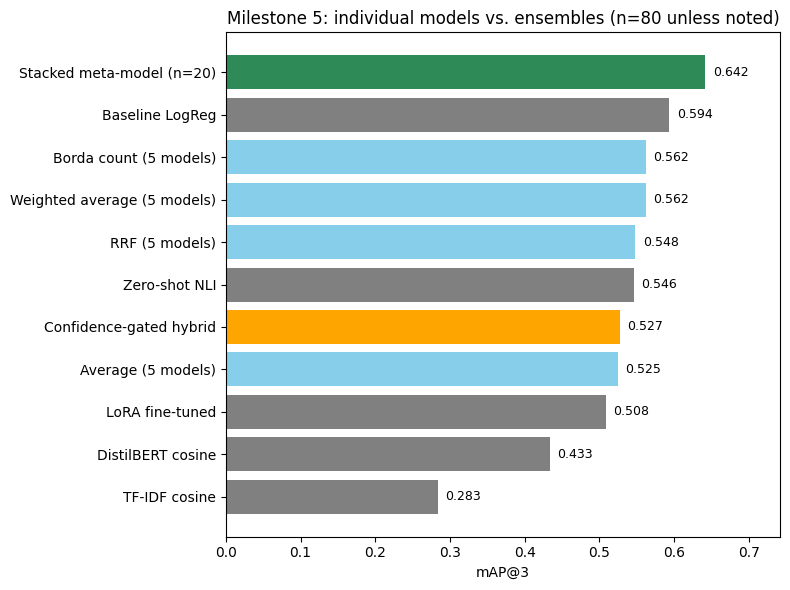

In [12]:
all_results = {**individual_map3, **ensemble_map3}
all_results['Stacked meta-model (n=20)'] = stack_map3
all_results['Confidence-gated hybrid'] = hybrid_map3

results_df = pd.Series(all_results).sort_values()
plt.figure(figsize=(8, 6))
colors = ['gray'] * len(individual_map3) + ['skyblue'] * len(ensemble_map3) + ['seagreen', 'orange']
color_map = dict(zip(all_results.keys(), colors))
bar_colors = [color_map[k] for k in results_df.index]
plt.barh(results_df.index, results_df.values, color=bar_colors)
plt.xlabel('mAP@3')
plt.title('Milestone 5: individual models vs. ensembles (n=80 unless noted)')
plt.xlim(0, max(results_df.values) + 0.1)
for i, v in enumerate(results_df.values):
    plt.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('../reports/milestone5_ensemble_comparison.png', dpi=120)
plt.show()

In [13]:
best_individual_name = max(individual_map3, key=individual_map3.get)
best_individual_score = individual_map3[best_individual_name]
n80_ensembles = {**ensemble_map3, 'Confidence-gated hybrid': hybrid_map3}
best_ensemble_name = max(n80_ensembles, key=n80_ensembles.get)
best_ensemble_score = n80_ensembles[best_ensemble_name]

print(f'Best individual model (n=80): {best_individual_name} = {best_individual_score:.4f}')
print(f'Best ensemble/hybrid (n=80):  {best_ensemble_name} = {best_ensemble_score:.4f}')
if best_ensemble_score > best_individual_score:
    print(f'-> ensembling won on this run, by {best_ensemble_score - best_individual_score:+.4f} mAP@3')
else:
    print(f'-> the single best model won on this run, by {best_individual_score - best_ensemble_score:+.4f} mAP@3 '
          f'over the best n=80 ensemble/hybrid (the n=20 stacked meta-model scored {stack_map3:.4f}, but on a '
          f'smaller/non-comparable held-out slice)')

Best individual model (n=80): Baseline LogReg = 0.5938
Best ensemble/hybrid (n=80):  Weighted average (5 models) = 0.5625
-> the single best model won on this run, by +0.0312 mAP@3 over the best n=80 ensemble/hybrid (the n=20 stacked meta-model scored 0.6417, but on a smaller/non-comparable held-out slice)


## 8. Takeaways

- Sorting a model's raw output (logits, cosine similarities, or
  probabilities -- the scale doesn't matter for this step) and reading
  off the top-3 option letters is literally one `argsort`/`sort_values`
  call; every model in this project already does exactly this.
- **Rank-based fusion (Borda/RRF) sidesteps a real problem**: TF-IDF
  cosine similarities, raw logits, and softmax probabilities aren't on
  comparable numeric scales, so naively averaging raw scores across
  models is questionable even after a per-row softmax. Fusing *rankings*
  instead avoids that assumption entirely.
- Whether ensembling actually helps here depends on how good the weakest
  members are: milestone 1/3 already showed some individual signals
  (plain TF-IDF, badly-retrieved RAG context) can sit at or below random
  guessing -- folding a weak model into an equal-weight average can drag a
  strong model like LoRA down rather than lifting the ensemble, which
  weighted averaging and confidence gating are both explicit attempts to
  guard against. Whichever number came out on top above, that's the
  concrete lesson: **ensembling is not automatically better than your
  best single model** -- it depends on which members are actually adding
  signal versus noise, which is why this notebook evaluates it rather
  than assumes it.
- With a real GPU-scale run (milestone 4's fine-tuning done properly on
  the full training set), the honest expectation is that the fine-tuned
  model dominates and the other 4 members contribute progressively less
  -- ensembling generally helps most when the members are closer in
  quality and make *different* mistakes, not when one member is trained
  directly on the task and the others are zero-shot/generic.